# Estimativas e tamanhos de efeito

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_05/01_estimativas_e_tamanhos_de_efeito.ipynb)

O guia definiu uma comparação como uma cadeia argumentativa. Este notebook
começa pela pergunta mais concreta: **quanto os grupos diferem na amostra ou no
corpus observado?**

## 1. Unidades, grupos e quantidade de interesse

Compare apenas unidades que tenham significado compatível. Aqui cada linha é um
documento; usaremos `local` para formar grupos e `palavras` como extensão
simulada. A média responde sobre a extensão média; a mediana, sobre a posição
central resistente a extremos; a proporção, sobre a frequência de uma condição.

![Diferença observada, incerteza do procedimento e relevância substantiva aparecem como três perguntas distintas ligadas em sequência.](imagens/01_diferenca_incerteza_relevancia.svg)

Defina a quantidade antes de calcular. Se $\hat{\theta}_A$ e
$\hat{\theta}_B$ são estimativas nos grupos, a diferença absoluta é:

$$
\Delta=\hat{\theta}_A-\hat{\theta}_B.
$$

O sinal depende da ordem declarada.

In [1]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_05'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente local: nenhuma clonagem necessária.


,count,mean,median,std
local,,,,
Capital,12,600.00,551.0,229.87
Interior,12,803.17,692.0,463.50


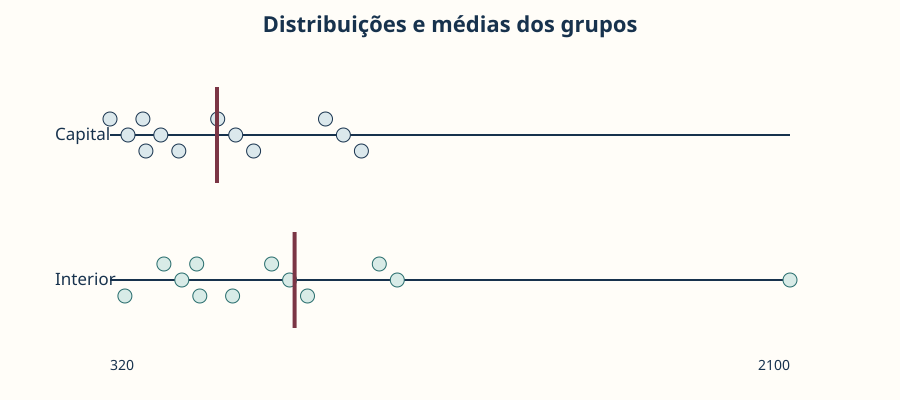

In [2]:
import pandas as pd
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd())) if str(Path.cwd()) not in sys.path else None
from graficos import estimativas_grupos
from IPython.display import display

dados = pd.read_csv("dados/documentos.csv")
grupos = dados.groupby("local")["palavras"]
resumo_grupos = grupos.agg(["count", "mean", "median", "std"])
display(resumo_grupos.round(2))
valores_capital = dados.loc[dados["local"].eq("Capital"), "palavras"].tolist()
valores_interior = dados.loc[dados["local"].eq("Interior"), "palavras"].tolist()
estimativas_grupos(valores_capital, valores_interior, "Capital", "Interior")

A tabela e o gráfico mostram distribuição, sobreposição e um caso extremo. Por
isso, uma única medida não deve apagar a forma dos grupos.

## 2. Médias, medianas e proporções

Para cada medida, calcularemos Capital menos Interior. A proporção corresponde
aos documentos cujo tema dominante é `educação`; ela não mede quanto cada texto
discute educação.

In [3]:
por_local = dados.groupby("local")
medidas = pd.DataFrame({
    "media_palavras": por_local["palavras"].mean(),
    "mediana_palavras": por_local["palavras"].median(),
    "proporcao_educacao": por_local["tema"].apply(lambda s: s.eq("educação").mean()),
})
diferencas = medidas.loc["Capital"] - medidas.loc["Interior"]
display(medidas.round(3))
diferencas.rename("Capital menos Interior").round(3)

,media_palavras,mediana_palavras,proporcao_educacao
local,,,
Capital,600.000,551.0,0.333
Interior,803.167,692.0,0.167


media_palavras       -203.167
mediana_palavras     -141.000
proporcao_educacao      0.167
Name: Capital menos Interior, dtype: float64

Média e mediana respondem a aspectos diferentes, e a diferença de proporções é
lida em pontos percentuais. A escolha deve preceder a observação do resultado.

## 3. Diferenças absolutas e relativas

Tomando B como referência, a diferença relativa é:

$$
\Delta_{rel}=\frac{\hat{\theta}_A-\hat{\theta}_B}{\hat{\theta}_B}.
$$

Ela muda ao inverter a referência e se torna instável quando o denominador se
aproxima de zero. Sempre apresente também a diferença absoluta e a unidade.

In [4]:
media_capital = medidas.loc["Capital", "media_palavras"]
media_interior = medidas.loc["Interior", "media_palavras"]
diferenca_absoluta = media_capital - media_interior
diferenca_relativa = diferenca_absoluta / media_interior
pd.Series({
    "diferença absoluta (palavras)": diferenca_absoluta,
    "diferença relativa a Interior": diferenca_relativa,
}).round(3)

diferença absoluta (palavras)   -203.167
diferença relativa a Interior     -0.253
dtype: float64

A diferença relativa produz uma narrativa proporcional, mas não informa a
variabilidade interna. Para comparar escalas, pode-se padronizar a diferença;
ainda assim, a escala original permanece indispensável.

## 4. Tamanho de efeito

Para duas médias, uma versão introdutória da diferença padronizada é:

$$
d=\frac{\bar{x}_A-\bar{x}_B}{s_p},\qquad
s_p=\sqrt{\frac{(n_A-1)s_A^2+(n_B-1)s_B^2}{n_A+n_B-2}}.
$$

`d` expressa a diferença em desvios-padrão combinados. Rótulos universais como
“pequeno” ou “grande” não substituem conhecimento substantivo, desenho dos dados
ou diferença bruta.

In [5]:
import math

a = dados.loc[dados["local"].eq("Capital"), "palavras"]
b = dados.loc[dados["local"].eq("Interior"), "palavras"]
desvio_combinado = math.sqrt(
    ((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1))
    / (len(a)+len(b)-2)
)
d_padronizado = (a.mean() - b.mean()) / desvio_combinado
pd.Series({"diferença bruta": a.mean()-b.mean(), "d padronizado": d_padronizado}).round(3)

diferença bruta   -203.167
d padronizado       -0.555
dtype: float64

O efeito padronizado resume separação relativa à dispersão, mas pode mudar com
um único caso influente. A etapa seguinte retorna aos registros.

## 5. Sensibilidade e relevância substantiva

Compare a diferença de médias com e sem D023, o extremo deliberado. Depois leia
os textos dos documentos com maiores e menores valores. Pergunte se `palavras`
representa extensão documental, intensidade do tema ou apenas um campo simulado.

In [6]:
sem_extremo = dados.loc[~dados["id_documento"].eq("D023")]
sensibilidade = pd.Series({
    "todos os registros": diferenca_absoluta,
    "sem D023": (
        sem_extremo.loc[sem_extremo["local"].eq("Capital"), "palavras"].mean()
        - sem_extremo.loc[sem_extremo["local"].eq("Interior"), "palavras"].mean()
    ),
})
display(sensibilidade.round(2))
dados.nlargest(3, "palavras")[["id_documento", "local", "palavras", "texto"]]

todos os registros   -203.17
sem D023              -85.27
dtype: float64

,id_documento,local,palavras,texto
22,D023,Interior,2100,A estrada e a máquina anunciam progresso e tam...
16,D017,Interior,1072,A escola noturna amplia a instrução pública e ...
15,D016,Interior,1025,A cidade debate higiene água saúde e cuidado c...


## Aplicação ao projeto Goodreads

As células seguintes aplicam as operações do notebook à base do projeto.
Especificação principal: **E2** (rótulo original sem os 1.274 livros
duvidosos): 4.638 livros de autoria feminina (F) e 4.542 de autoria masculina
(M). A ordem das diferenças é sempre **F − M**: valor negativo indica menos
reconhecimento para livros de autoras.

In [7]:
# Localiza a pasta do projeto Goodreads (localmente ou no Colab, se a pasta for enviada para /content)
import sys
from pathlib import Path

CANDIDATOS = [Path("../projeto_goodreads"), Path("projeto_goodreads"), Path("/content/projeto_goodreads")]
PROJETO = next((c.resolve() for c in CANDIDATOS if (c / "preparar_base.py").exists()), None)
if PROJETO is None:
    raise FileNotFoundError(
        "Pasta projeto_goodreads não encontrada. Coloque-a ao lado das pastas unidade_0X "
        "ou, no Colab, envie-a para /content."
    )
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))
print("Projeto localizado:", (PROJETO / "preparar_base.py").exists())
from preparar_base import carregar_base_analitica
import numpy as np
import pandas as pd
from IPython.display import display

base = carregar_base_analitica()
ESPEC = {"E1 original": "genero_E1_original",
         "E2 sem duvidosos (principal)": "genero_E2_sem_duvidosos",
         "E3 reclassificada": "genero_E3_reclassificado"}
GRUPO = "genero_E2_sem_duvidosos"
e2 = base[base[GRUPO].notna()].copy()
e2["muito_avaliado"] = e2["n_avaliacoes"] >= 10_000
F = e2[GRUPO].eq("feminino")
M = e2[GRUPO].eq("masculino")
print("Especificação principal E2:", int(F.sum()), "livros de autoria feminina e", int(M.sum()), "de autoria masculina")

Projeto localizado: True
Especificação principal E2: 4638 livros de autoria feminina e 4542 de autoria masculina


**Médias, medianas, proporções e diferenças absolutas e relativas** (F − M; relativa à autoria masculina).

In [8]:
por_grupo = e2.groupby(GRUPO)
medidas_gr = pd.DataFrame({
    "n": por_grupo.size(),
    "mediana_avaliacoes": por_grupo["n_avaliacoes"].median(),
    "media_log10_avaliacoes": por_grupo["log10_avaliacoes"].mean(),
    "media_geometrica_avaliacoes": 10 ** por_grupo["log10_avaliacoes"].mean(),
    "proporcao_10mil_ou_mais": por_grupo["muito_avaliado"].mean(),
    "mediana_resenhas": por_grupo["n_resenhas"].median(),
    "mediana_taxa_resenhas": por_grupo["taxa_resenhas"].median(),
})
display(medidas_gr.round(3))
dif = medidas_gr.loc["feminino"] - medidas_gr.loc["masculino"]
rel = dif / medidas_gr.loc["masculino"]
pd.DataFrame({"feminino menos masculino": dif, "relativa à autoria masculina": rel}).drop("n").round(3)

,n,mediana_avaliacoes,media_log10_avaliacoes,media_geometrica_avaliacoes,proporcao_10mil_ou_mais,mediana_resenhas,mediana_taxa_resenhas
genero_E2_sem_duvidosos,,,,,,,
feminino,4638,3129.0,3.498,3148.637,0.293,320.0,0.114
masculino,4542,5217.5,3.675,4726.427,0.379,360.5,0.076


,feminino menos masculino,relativa à autoria masculina
mediana_avaliacoes,-2088.500,-0.400
media_log10_avaliacoes,-0.176,-0.048
media_geometrica_avaliacoes,-1577.790,-0.334
proporcao_10mil_ou_mais,-0.086,-0.228
mediana_resenhas,-40.500,-0.112
mediana_taxa_resenhas,0.038,0.493


**Tamanho de efeito padronizado** (calculado em log10 para as avaliações, por causa da assimetria).

In [9]:
import math
a = e2.loc[F, "log10_avaliacoes"]
b = e2.loc[M, "log10_avaliacoes"]
s_p = math.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
d_log = (a.mean() - b.mean()) / s_p
ta, tb = e2.loc[F, "taxa_resenhas"], e2.loc[M, "taxa_resenhas"]
s_pt = math.sqrt(((len(ta) - 1) * ta.var(ddof=1) + (len(tb) - 1) * tb.var(ddof=1)) / (len(ta) + len(tb) - 2))
pd.Series({
    "diferença bruta em log10 (avaliações)": a.mean() - b.mean(),
    "razão de médias geométricas (F/M)": 10 ** (a.mean() - b.mean()),
    "d padronizado (log10 avaliações)": d_log,
    "diferença bruta na taxa de resenhas": ta.mean() - tb.mean(),
    "d padronizado (taxa de resenhas)": (ta.mean() - tb.mean()) / s_pt,
}).round(3)

diferença bruta em log10 (avaliações)   -0.176
razão de médias geométricas (F/M)        0.666
d padronizado (log10 avaliações)        -0.181
diferença bruta na taxa de resenhas      0.037
d padronizado (taxa de resenhas)         0.333
dtype: float64

**Sensibilidade às especificações de gênero e ao período.**

In [10]:
def comparar(dados, coluna):
    d = dados[dados[coluna].notna()]
    g = d.groupby(coluna)
    med = g["n_avaliacoes"].median()
    return pd.Series({
        "n_fem": int(g.size()["feminino"]), "n_masc": int(g.size()["masculino"]),
        "razao_medianas_aval": med["feminino"] / med["masculino"],
        "dif_log10_media": g["log10_avaliacoes"].mean()["feminino"] - g["log10_avaliacoes"].mean()["masculino"],
        "dif_mediana_taxa": g["taxa_resenhas"].median()["feminino"] - g["taxa_resenhas"].median()["masculino"],
    })

linhas = {}
for nome, coluna in ESPEC.items():
    linhas[(nome, "todos os anos")] = comparar(base, coluna)
    linhas[(nome, "1990–2019")] = comparar(base[base["ano_publicacao"] >= 1990], coluna)
    linhas[(nome, "2010–2019")] = comparar(base[base["ano_publicacao"] >= 2010], coluna)
pd.DataFrame(linhas).T.round(3)

n_fem  n_masc  \
E1 original                  todos os anos  4638.0  5816.0   
                             1990–2019      4154.0  4183.0   
                             2010–2019      3043.0  2362.0   
E2 sem duvidosos (principal) todos os anos  4638.0  4542.0   
                             1990–2019      4154.0  2987.0   
                             2010–2019      3043.0  1514.0   
E3 reclassificada            todos os anos  5912.0  4542.0   
                             1990–2019      5350.0  2987.0   
                             2010–2019      3891.0  1514.0   

                                            razao_medianas_aval  \
E1 original                  todos os anos                0.708   
                             1990–2019                    0.843   
                             2010–2019                    1.342   
E2 sem duvidosos (principal) todos os anos                0.600   
                             1990–2019                    0.724   
                             2010–2019                    1.459   
E3 reclassificada            todos os anos                0.564   
                             1990–2019                    0.703   
                             2010–2019                    1.405   

                                            dif_log10_media  dif_mediana_taxa  
E1 original                  todos os anos           -0.108             0.027  
                             1990–2019               -0.014             0.011  
                             2010–2019                0.165            -0.010  
E2 sem duvidosos (principal) todos os anos           -0.176             0.038  
                             1990–2019               -0.061             0.020  
                             2010–2019                0.192            -0.010  
E3 reclassificada            todos os anos           -0.206             0.040  
                             1990–2019               -0.084             0.021  
                             2010–2019                0.166            -0.007

**Comparação dentro de estratos** (ano de publicação e gênero literário).

In [11]:
# Comparação dentro de estratos: mesma diferença calculada ano a ano e gênero a gênero,
# depois resumida por média ponderada pelo número de livros do estrato.
def dentro_de_estratos(dados, estrato, minimo=10):
    linhas = []
    for valor, d in dados.groupby(estrato, observed=True):
        n_f, n_m = int(d[GRUPO].eq("feminino").sum()), int(d[GRUPO].eq("masculino").sum())
        if n_f >= minimo and n_m >= minimo:
            linhas.append({estrato: valor, "n_fem": n_f, "n_masc": n_m,
                           "dif_log10": d.loc[d[GRUPO].eq("feminino"), "log10_avaliacoes"].mean()
                                        - d.loc[d[GRUPO].eq("masculino"), "log10_avaliacoes"].mean(),
                           "razao_medianas": d.loc[d[GRUPO].eq("feminino"), "n_avaliacoes"].median()
                                             / d.loc[d[GRUPO].eq("masculino"), "n_avaliacoes"].median()})
    tabela = pd.DataFrame(linhas)
    pesos = tabela["n_fem"] + tabela["n_masc"]
    resumo = (tabela["dif_log10"] * pesos).sum() / pesos.sum()
    return tabela, resumo, pesos.sum()

por_ano, resumo_ano, n_ano = dentro_de_estratos(e2[e2["ano_publicacao"].between(1990, 2018)], "ano_publicacao")
por_genero, resumo_genero, n_genero = dentro_de_estratos(e2, "genero_1", minimo=30)
bruta_1990 = (e2.loc[F & e2["ano_publicacao"].between(1990, 2018), "log10_avaliacoes"].mean()
              - e2.loc[M & e2["ano_publicacao"].between(1990, 2018), "log10_avaliacoes"].mean())
display(pd.Series({
    "diferença bruta em log10 (1990–2018)": bruta_1990,
    "diferença média dentro de cada ano (1990–2018)": resumo_ano,
    "diferença média dentro de cada gênero literário (≥30 por grupo)": resumo_genero,
    "livros cobertos pela comparação por gênero literário": n_genero,
}).round(3))
por_genero.sort_values("razao_medianas").round(3)

diferença bruta em log10 (1990–2018)                                 -0.060
diferença média dentro de cada ano (1990–2018)                        0.131
diferença média dentro de cada gênero literário (≥30 por grupo)      -0.066
livros cobertos pela comparação por gênero literário               7080.000
dtype: float64

,genero_1,n_fem,n_masc,dif_log10,razao_medianas
10,Science Fiction,126,300,-0.396,0.319
5,Horror,54,195,-0.309,0.474
4,Historical,426,207,-0.163,0.476
2,Fantasy,675,483,-0.192,0.604
8,Poetry,44,115,-0.311,0.642
7,Nonfiction,174,296,-0.241,0.650
13,Young Adult,657,210,-0.092,0.833
11,Sequential Art,99,88,0.040,1.009
3,Fiction,432,759,0.020,1.043
6,Mystery,189,153,0.084,1.070


In [12]:
# Os gêneros literários também diferem na idade dos livros. Repetimos a comparação por gênero
# apenas com livros de 2010–2019 e calculamos a taxa de resenhas dentro de cada ano.
recentes = e2[e2["ano_publicacao"].between(2010, 2019)]
por_genero_rec, resumo_genero_rec, n_genero_rec = dentro_de_estratos(recentes, "genero_1", minimo=30)
taxa_ano = []
for ano, d in e2[e2["ano_publicacao"].between(1990, 2018)].groupby("ano_publicacao"):
    f, m = d.loc[d[GRUPO].eq("feminino"), "taxa_resenhas"], d.loc[d[GRUPO].eq("masculino"), "taxa_resenhas"]
    if len(f) >= 10 and len(m) >= 10:
        taxa_ano.append({"ano": ano, "n": len(f) + len(m), "dif_mediana_taxa": f.median() - m.median()})
taxa_ano = pd.DataFrame(taxa_ano)
display(pd.Series({
    "diferença média em log10 dentro de cada gênero, só 2010–2019": resumo_genero_rec,
    "livros cobertos": n_genero_rec,
    "diferença média da mediana da taxa de resenhas dentro de cada ano (1990–2018)":
        (taxa_ano["dif_mediana_taxa"] * taxa_ano["n"]).sum() / taxa_ano["n"].sum(),
    "anos em que a taxa mediana de autoras é maior": f"{int((taxa_ano['dif_mediana_taxa'] > 0).sum())} de {len(taxa_ano)}",
}))
por_genero_rec.sort_values("razao_medianas").round(3)

diferença média em log10 dentro de cada gênero, só 2010–2019                     0.162627
livros cobertos                                                                      3515
diferença média da mediana da taxa de resenhas dentro de cada ano (1990–2018)   -0.009032
anos em que a taxa mediana de autoras é maior                                    14 de 29
dtype: object

,genero_1,n_fem,n_masc,dif_log10,razao_medianas
5,Nonfiction,74,86,-0.061,0.572
7,Science Fiction,82,116,-0.073,0.732
2,Historical,271,87,0.099,1.276
0,Fantasy,501,246,0.151,1.445
8,Young Adult,511,131,0.099,1.538
6,Romance,633,158,0.271,1.732
3,Horror,37,82,0.000,1.900
1,Fiction,159,171,0.341,1.983
4,Mystery,109,61,0.337,2.341


**Casos que qualificam o resultado.**

In [13]:
# Casos que qualificam o resultado: os livros mais avaliados e dois gêneros com sentidos opostos
display(e2.nlargest(4, "n_avaliacoes")[["id_livro", "titulo", "autor", GRUPO, "ano_publicacao", "genero_1", "n_avaliacoes"]])
romance = e2[e2["genero_1"].eq("Romance")]
display(romance.groupby(GRUPO).agg(n=("id_livro", "size"),
                                   mediana_avaliacoes=("n_avaliacoes", "median"),
                                   mediana_ano=("ano_publicacao", "median")))
ficcao_cientifica = e2[e2["genero_1"].eq("Science Fiction")]
ficcao_cientifica.groupby(GRUPO).agg(n=("id_livro", "size"),
                                     mediana_avaliacoes=("n_avaliacoes", "median"),
                                     mediana_ano=("ano_publicacao", "median"),
                                     antes_de_1990=("ano_publicacao", lambda s: (s < 1990).mean()))

,id_livro,titulo,autor,genero_E2_sem_duvidosos,ano_publicacao,genero_1,n_avaliacoes
579,2657,To Kill a Mockingbird,Harper Lee,feminino,1960,Classics,3819418
578,4671,The Great Gatsby,F. Scott Fitzgerald,masculino,1925,Classics,3203463
2276,11870085,The Fault in Our Stars,John Green,masculino,2012,Young Adult,2946242
2047,1885,Pride and Prejudice,Jane Austen,feminino,1813,Classics,2504844


,n,mediana_avaliacoes,mediana_ano
genero_E2_sem_duvidosos,,,
feminino,735,1744.0,2013.0
masculino,195,1027.0,2013.0


,n,mediana_avaliacoes,mediana_ano,antes_de_1990
genero_E2_sem_duvidosos,,,,
feminino,126,1723.0,2012.0,0.119048
masculino,300,5401.5,2004.0,0.336667


> **Nota sobre atividades em dupla, trio ou revisão por pares.** Esta resolução
> foi produzida por uma única pessoa. Onde o roteiro pede colegas, apresento uma
> **revisão crítica simulada**, guiada pelas perguntas do roteiro. Ela não
> substitui o trabalho e o parecer de colegas reais.

## U05-A02 — Atividade integrada — quadro de estimativas

**Modalidade:** individual e revisão em dupla. **Tempo:** 25 + 10 minutos.

1. escolha dois grupos e uma quantidade coerente com sua pergunta;
2. apresente a distribuição e ao menos duas medidas pertinentes;
3. calcule diferença absoluta e, se defensável, relativa ou padronizada;
4. inspecione dois casos que qualifiquem o resultado;
5. escreva o que a diferença significa e o que não significa.

**Minha estimativa e justificativa:**
*Grupos:* livros de autoria feminina (F) e masculina (M), especificação E2.
*Quantidades:* alcance (número de avaliações) e engajamento relativo (taxa de
resenhas por avaliação). A distribuição do alcance foi apresentada na Unidade 4
(Figura 2): muito assimétrica, por isso escolhi duas medidas resistentes:
**mediana** e **média em escala log10** (equivalente à média geométrica).

| Medida | F | M | F − M | Relativa a M |
|---|---:|---:|---:|---:|
| mediana de avaliações | 3.129 | 5.218 | −2.089 | −40% |
| média geométrica de avaliações | 3.149 | 4.726 | −1.578 | −33% |
| proporção com 10 mil avaliações ou mais | 29,3% | 37,9% | −8,6 pontos | −23% |
| mediana de resenhas | 320 | 361 | −41 | −11% |
| mediana da taxa de resenhas | 0,114 | 0,076 | +0,038 | +49% |

*Diferença padronizada:* d = −0,18 para log10 das avaliações e d = +0,33 para a
taxa de resenhas. Os dois valores indicam grande sobreposição entre as
distribuições. Não uso rótulos como “pequeno” ou “grande”: o valor só ganha
sentido na escala original e no contexto.

*Sensibilidade (a parte decisiva):*
- *Especificação de gênero:* a razão entre as medianas é 0,71 (E1), 0,60 (E2) e
  0,56 (E3). A auditoria do rótulo aumenta a diferença.
- *Período:* com livros de 1990 a 2019, a razão em E2 sobe para 0,72; com
  livros de **2010 a 2019, ela se inverte para 1,46**: livros recentes de autoras
  têm mediana maior que livros recentes de autores, nas três especificações.
- *Dentro de cada ano (1990–2018):* a diferença bruta em log10 é −0,06, mas a
  média das diferenças calculadas ano a ano é **+0,13**. Comparando livros do
  mesmo ano, os de autoras recebem mais avaliações.
- *Dentro de cada gênero literário:* média das diferenças de −0,07, com grande
  variação: ficção científica (razão de medianas de 0,32) e horror (0,47) no
  extremo negativo; romance (1,70) e clássicos (1,62) no positivo. Restrita a
  2010–2019, a média dentro dos gêneros passa a **+0,16**; só não ficção (0,57) e
  ficção científica (0,73) continuam favorecendo livros de autores.
- *Taxa de resenhas:* a vantagem agregada dos livros de autoras (+0,038)
  desaparece quando se compara dentro de cada ano (média de −0,009; maior para
  autoras em 14 de 29 anos). A hipótese H2 da Unidade 4 não se sustenta: a
  diferença era produzida pela composição temporal.

**Casos inspecionados:**
1. *Ficção científica.* A mediana de livros de autores é 5.402 e a de autoras,
   1.723. Mas 34% dos livros de autores desse gênero são anteriores a 1990,
   contra 12% dos de autoras (anos medianos 2004 e 2012). Parte da diferença é
   idade: clássicos do gênero acumularam décadas de avaliações. Mesmo entre
   2010 e 2019, porém, a razão fica em 0,73: a desvantagem diminui, não some.
2. *Romance.* Livros de autoras têm mediana de 1.744 contra 1.027 de autores, e
   os dois grupos têm o mesmo ano mediano (2013). Aqui a composição temporal
   não explica a diferença, que favorece as autoras. Romance é também o gênero
   com mais livros de autoras (735 contra 195).

**Relevância substantiva e limite:** a diferença agregada é real *no recorte*:
livros de autoras têm mediana 40% menor. Mas ela não significa que, em
condições semelhantes, livros de autoras recebam menos atenção: comparando
livros do mesmo ano, ocorre o contrário na maior parte do período. O resultado
agregado reflete sobretudo um **cânone acumulado**: livros antigos, muito
avaliados e majoritariamente de autores (80% dos clássicos do recorte). Isso
também é uma forma de desigualdade no reconhecimento, mas de natureza
histórica, ligada ao que foi preservado e ensinado. Limite: o critério de
seleção do recorte é desconhecido; se ele selecionou livros recentes e antigos
por regras diferentes, todas essas comparações herdam essa diferença.

*Revisão simulada da dupla:* o quadro mostra várias medidas, mas precisa
declarar qual é a principal para evitar escolher depois de ver o resultado.
*Resposta:* a medida principal, declarada antes dos cálculos de sensibilidade,
é a **diferença de médias em log10 das avaliações (F − M)**; a mediana é a
alternativa.

Leve o quadro ao Notebook 02. Ele será acompanhado por uma avaliação explícita
da variabilidade e das condições em que a inferência é pertinente.